#### importing libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### Loading Cleaned dataset

In [2]:
df_clean = pd.read_csv(r"D:\Auspify_Data_Science_Internship\Task_02_Netflix_Data_EDA\dataset\netflix_cleaned.csv")

In [3]:
df_clean

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,90,min
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",1,Season
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",125,min
...,...,...,...,...,...,...,...,...,...,...,...,...
8781,s8797,TV Show,Yunus Emre,NaN,Turkey,2017-01-17,2016,TV-PG,2 Seasons,"International TV Shows, TV Dramas",2,Seasons
8782,s8798,TV Show,Zak Storm,NaN,United States,2018-09-13,2016,TV-Y7,3 Seasons,Kids' TV,3,Seasons
8783,s8801,TV Show,Zindagi Gulzar Hai,NaN,Pakistan,2016-12-15,2012,TV-PG,1 Season,"International TV Shows, Romantic TV Shows, TV ...",1,Season
8784,s8784,TV Show,Yoko,NaN,Pakistan,2018-06-23,2016,TV-Y,1 Season,Kids' TV,1,Season


In [6]:
print("dataset shape: ",df_clean.shape)

dataset shape:  (8786, 12)


In [7]:
df_clean.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,90,min
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",1,Season
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",125,min


In [11]:
df_clean.info()
df_clean.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 8786 entries, 0 to 8785
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   show_id         8786 non-null   str  
 1   type            8786 non-null   str  
 2   title           8786 non-null   str  
 3   director        6199 non-null   str  
 4   country         8499 non-null   str  
 5   date_added      8786 non-null   str  
 6   release_year    8786 non-null   int64
 7   rating          8786 non-null   str  
 8   duration        8786 non-null   str  
 9   listed_in       8786 non-null   str  
 10  duration_value  8786 non-null   int64
 11  duration_unit   8786 non-null   str  
dtypes: int64(2), str(10)
memory usage: 1.7 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8786,8786,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8786,2,Movie,6123,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8786,8786,Dick Johnson Is Dead,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6199,4527,Rajiv Chilaka,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,8499,85,United States,3240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8786,1713,2020-01-01,110,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8786.0,NaN,NaN,NaN,2014.181766,8.827137,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8786,14,TV-MA,3204,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8786,220,1 Season,1790,NaN,NaN,NaN,NaN,NaN,NaN,NaN
listed_in,8786,513,"Dramas, International Movies",362,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
# Count content types
type_counts = df_clean['type'].value_counts()

print(type_counts)

# Calculate percentages
type_percentage = df_clean['type'].value_counts(normalize=True) * 100

print("\nPercentage Distribution:")
print(type_percentage.round(2))

type
Movie      6123
TV Show    2663
Name: count, dtype: int64

Percentage Distribution:
type
Movie      69.69
TV Show    30.31
Name: proportion, dtype: float64


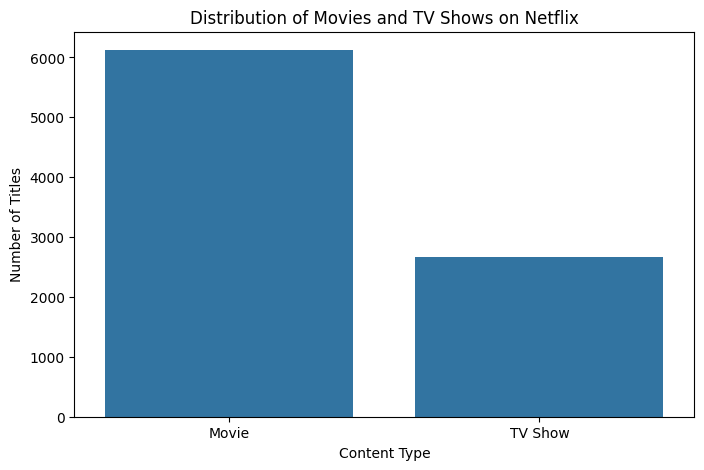

In [14]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x='type')

plt.title('Distribution of Movies and TV Shows on Netflix')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')

plt.show()

#### objective : To identify which countries contribute the most content to Netflix.

In [ ]:
country_df = df_clean.dropna(subset=['country']).copy()

country_df['country'] = country_df['country'].str.split(',')

country_df = country_df.explode('country') # explode: It converts multiple countries in one cell into separate rows.

country_df['country'] = country_df['country'].str.strip()

#### Top 10 countries

In [16]:
top_countries = country_df['country'].value_counts().head(10)

print(top_countries)

country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64


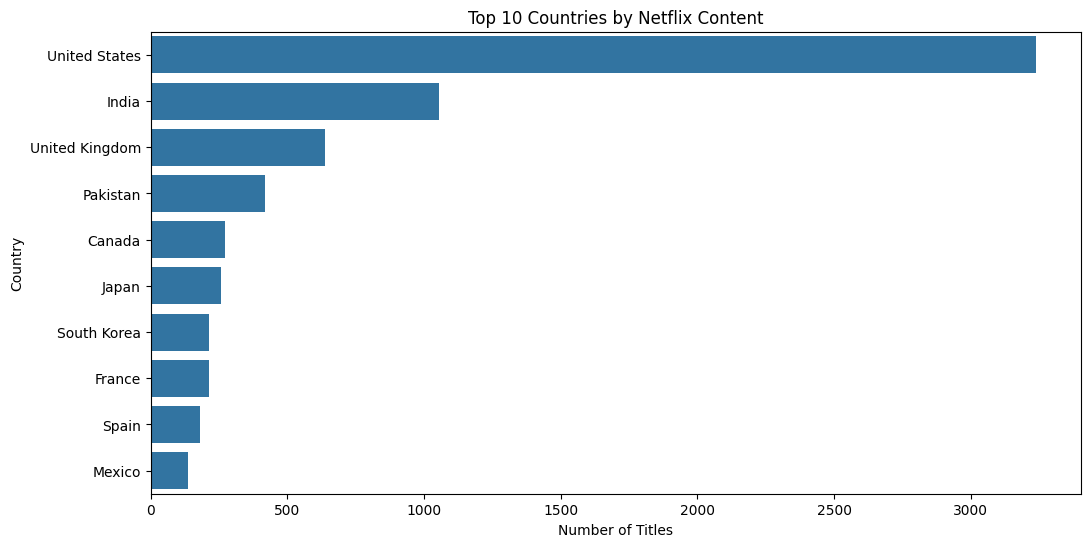

In [17]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title('Top 10 Countries by Netflix Content')
plt.xlabel('Number of Titles')
plt.ylabel('Country')

plt.show()

#### identifying which audience rating appears most frequently.

In [18]:
rating_counts = df_clean['rating'].value_counts()

print(rating_counts.head(10))

rating
TV-MA    3204
TV-14    2155
TV-PG     861
R         798
PG-13     490
TV-Y7     333
TV-Y      306
PG        287
TV-G      220
NR         79
Name: count, dtype: int64


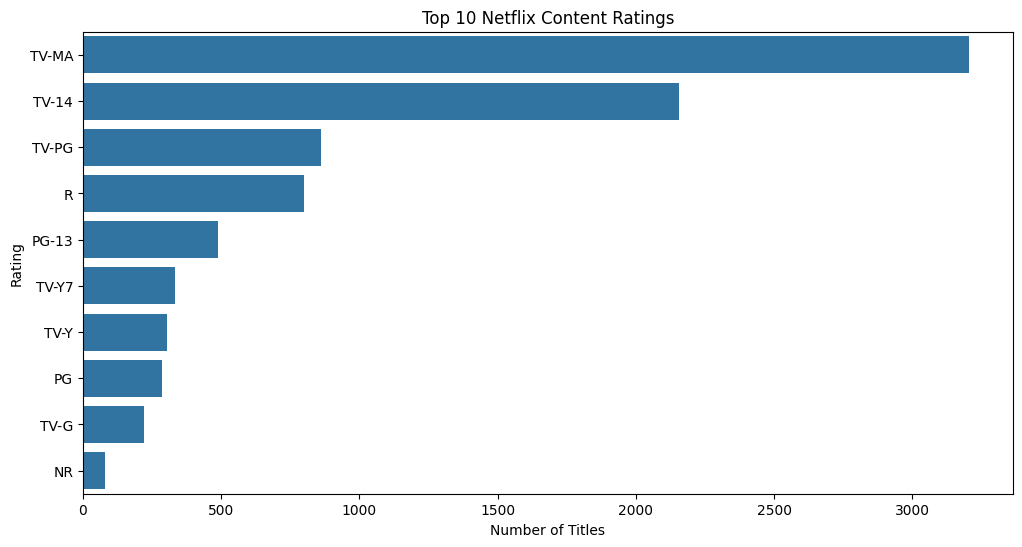

In [19]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=rating_counts.head(10).values,
    y=rating_counts.head(10).index
)

plt.title('Top 10 Netflix Content Ratings')
plt.xlabel('Number of Titles')
plt.ylabel('Rating')

plt.show()

Insight: TV-MA is the most common content rating on Netflix, followed by TV-14. This indicates a substantial presence of mature-audience and teen-oriented content in the Netflix catalogue.

#### how Netflix's content library has evolved over the years

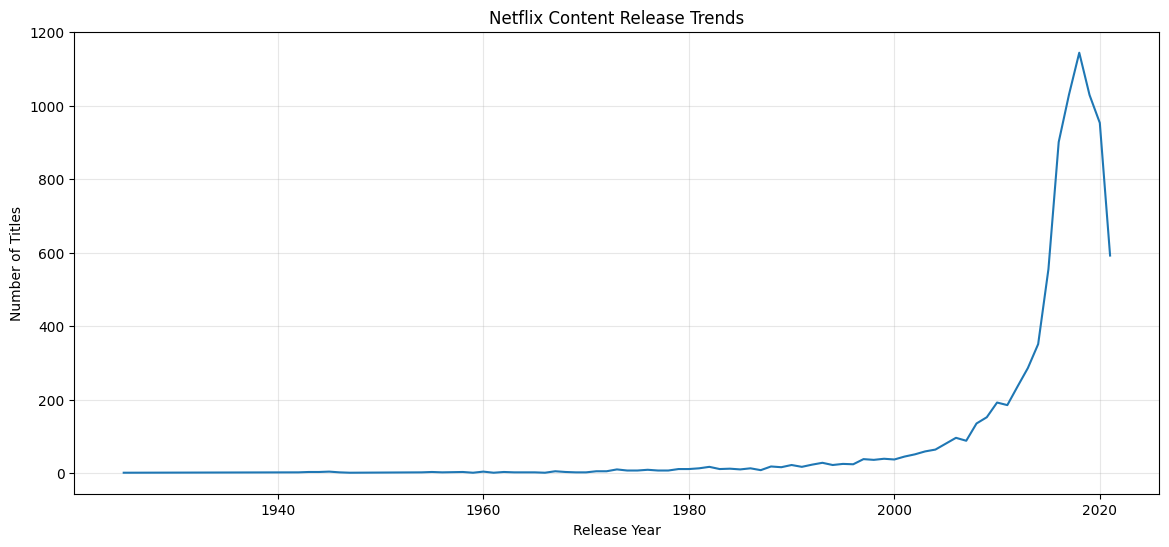

In [20]:
year_counts = df_clean['release_year'].value_counts().sort_index()

plt.figure(figsize=(14, 6))

plt.plot(year_counts.index, year_counts.values)

plt.title('Netflix Content Release Trends')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.grid(alpha=0.3)
plt.show()

In [21]:
print(df_clean['release_year'].value_counts().head(10))

release_year
2018    1144
2017    1030
2019    1029
2020     953
2016     901
2021     592
2015     555
2014     351
2013     286
2012     236
Name: count, dtype: int64


Insight: The year 2018 recorded the highest number of Netflix titles in the dataset, with 1,144 titles. The period from 2017 to 2020 also shows a high concentration of content releases.

#### Movie Duration Analysis

In [22]:
movies = df_clean[df_clean['type'] == 'Movie'].copy()

In [23]:
movies['duration_value'].describe()

count    6123.000000
mean       99.572595
std        28.282615
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_value, dtype: float64

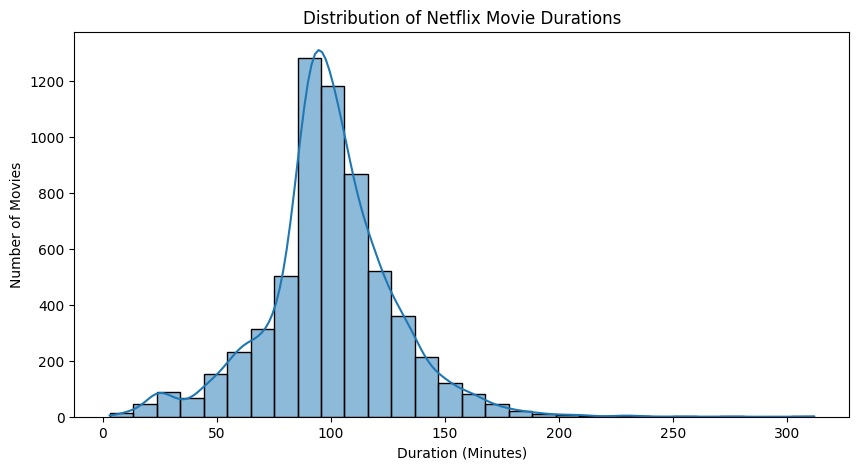

In [24]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=movies,
    x='duration_value',
    bins=30,
    kde=True
)

plt.title('Distribution of Netflix Movie Durations')
plt.xlabel('Duration (Minutes)')
plt.ylabel('Number of Movies')

plt.show()

#### calculateing the actual statistics

In [25]:
print("Average:", movies['duration_value'].mean())
print("Median:", movies['duration_value'].median())
print("Mode:", movies['duration_value'].mode()[0])
print("Minimum:", movies['duration_value'].min())
print("Maximum:", movies['duration_value'].max())

Average: 99.57259513310468
Median: 98.0
Mode: 90
Minimum: 3
Maximum: 312


In [26]:
under_120 = (
    movies['duration_value'] < 120
).sum()

percentage = (
    under_120 / len(movies)
) * 100

print("Movies under 120 minutes:", under_120)
print("Percentage:", round(percentage, 2), "%")

Movies under 120 minutes: 4927
Percentage: 80.47 %


Insight:The distribution of Netflix movie durations is positively skewed, with most movies concentrated between approximately 80 and 120 minutes. A smaller proportion of movies have significantly longer runtimes.

#### Genre Analysis

In [28]:
genre_df = df_clean['listed_in'].dropna().str.split(',')

genre_df = genre_df.explode().str.strip()

top_genres = genre_df.value_counts().head(10)

print(top_genres)

listed_in
International Movies        2751
Dramas                      2423
Comedies                    1673
International TV Shows      1348
Documentaries                869
Action & Adventure           859
TV Dramas                    761
Independent Movies           755
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


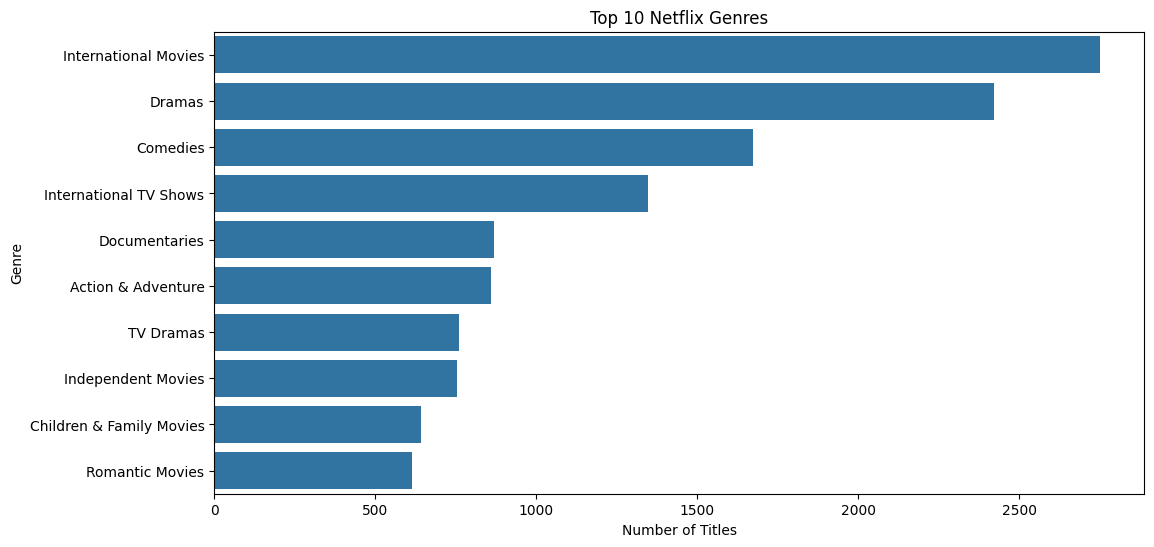

In [29]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title('Top 10 Netflix Genres')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')

plt.show()

Insight: International Movies is the most frequently represented genre in the Netflix dataset, followed by Dramas and Comedies. This suggests that Netflix offers a diverse content library with substantial representation of international films and drama-based content.